In [1]:
import json
import numpy as np, pandas as pd, geopandas as gpd
import igraph as ig, leidenalg
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from pathlib import Path

data = Path("../data")
TREAT = "#FFB136"     
CONTROL = "#4B9C7A"   
PALETTE = ["#4C72B0", "#8172B3", "#937860", "#DA8BC3", "#64B5CD", "#6B4C9A", "#B07AA1",
           "#2B3A67", "#A0CBE8", "#9D7660", "#7F7F7F", "#17557A", "#5B5B8A", "#C49C94"]  


def diffusion_kernel(W, beta=0.8, K=5):
    P = np.eye(len(W)) 
    out = np.zeros_like(W)
    for k in range(1, K + 1):
        P = P @ W
        out += beta**k * P
    return out


def pareto(df):
    d = df[(df["dist"] > 0) & np.isfinite(df["dist"]) & np.isfinite(df["ps"])].sort_values("ps")
    keep, best = [], -np.inf
    for _, r in d.iterrows():
        keep.append(r["dist"] > best)
        best = max(best, r["dist"])
    return d[keep]

## Boston Free Fare
CPM at γ=0.0025

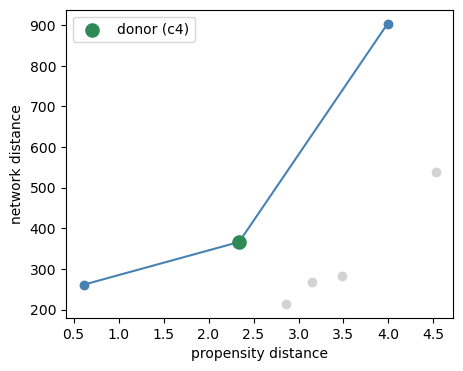

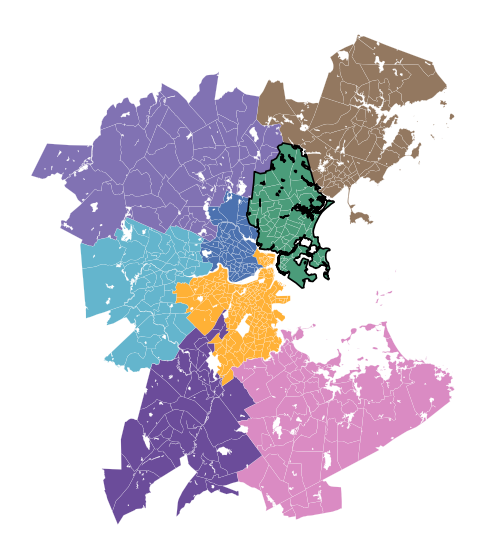

In [2]:
g = gpd.read_file(data/"free_fare/demographics/tracts.geojson")
g["GEOID"] = g["GEOID"].astype(str)
nodes = sorted(g["GEOID"])
idx = {n: i for i, n in enumerate(nodes)}
flows = pd.read_parquet(data/"free_fare/flows/flows.parquet")

W = np.zeros((len(nodes), len(nodes)))

for s, t, wt in flows[["source", "target", "weight"]].itertuples(index=False):
    W[idx[s], idx[t]] = wt



graph = ig.Graph(n=len(nodes), edges=list(zip(*np.where(W > 0))), directed=True)
graph.es["weight"] = W[W > 0].tolist()
members = [leidenalg.find_partition(graph, leidenalg.CPMVertexPartition, weights="weight",
            seed=s, n_iterations=-1, resolution_parameter=0.0025).membership for s in range(43, 143)]

co_assign = np.zeros((len(nodes), len(nodes)))

for m in members:
    m = np.array(m)
    for c in np.unique(m):
        i = np.where(m == c)[0]
        co_assign[np.ix_(i, i)] += 1

co_assign /= len(members)

labels = fcluster(linkage(squareform(np.clip(1 - co_assign, 0, None), checks=False), "average"), 0.5, "distance")
community = {nodes[i]: int(labels[i]) for i in range(len(nodes))}

g["community"] = g["GEOID"].map(community)
frac = g.groupby("community")["treated"].apply(lambda s: (s == True).mean())
treated_comms = set(frac[frac >= 0.10].index)

treated_ids = [idx[x] for x in g.loc[g["community"].isin(treated_comms), "GEOID"]]


Wd = diffusion_kernel(W)

feats = ["median_income", "trans.public", "prop.black", "prop.bachelor", "age.total"]
cd = g.groupby("community")[feats].mean().reset_index()
X = StandardScaler().fit_transform(cd[feats].fillna(0))
ps = np.clip(LogisticRegression(max_iter=1000).fit(X, cd["community"].isin(treated_comms).astype(int)).predict_proba(X)[:, 1], 1e-6, 1 - 1e-6)
cd["logit"] = np.log(ps / (1 - ps))
base = cd.loc[cd["community"].isin(treated_comms), "logit"].mean()


dist = []
for c in cd["community"]:
    if c in treated_comms:
        continue
    ino = [idx[x] for x in g.loc[g["community"] == c, "GEOID"]]
    score = Wd[np.ix_(ino, treated_ids)].mean()
    dist.append({"community": int(c), "dist": 1/score if score > 0 else np.nan,
                 "ps": abs(cd.loc[cd["community"] == c, "logit"].iloc[0] - base)})

dist = pd.DataFrame(dist)
front = pareto(dist)


plt.figure(figsize=(5, 4))
plt.scatter(dist["ps"], dist["dist"], color="lightgray")
plt.plot(front["ps"], front["dist"], "-o", color="steelblue")
sel = dist[dist.community == 4]
plt.scatter(sel["ps"], sel["dist"], color="seagreen", s=90, zorder=5, label="donor (c4)")
plt.xlabel("propensity distance")
plt.ylabel("network distance")
plt.legend()
plt.show()


sub = g.dropna(subset=["community"]).copy(); sub["community"] = sub["community"].astype(int)
others = [c for c in sorted(sub["community"].unique()) if c not in treated_comms and c != 4]
color = {c: PALETTE[i % len(PALETTE)] for i, c in enumerate(others)}

for c in treated_comms: 
    color[c] = TREAT

color[4] = CONTROL
fig, ax = plt.subplots(figsize=(7, 7))
sub.plot(ax=ax, color=sub["community"].map(color), linewidth=0.1, edgecolor="white")
sub[sub["community"] == 4].dissolve().plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1.2)
ax.set_axis_off()
plt.show()

## NYC Congestion Relief Zone
CPM γ=0.002

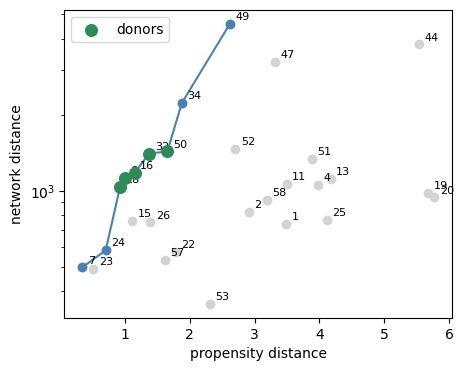

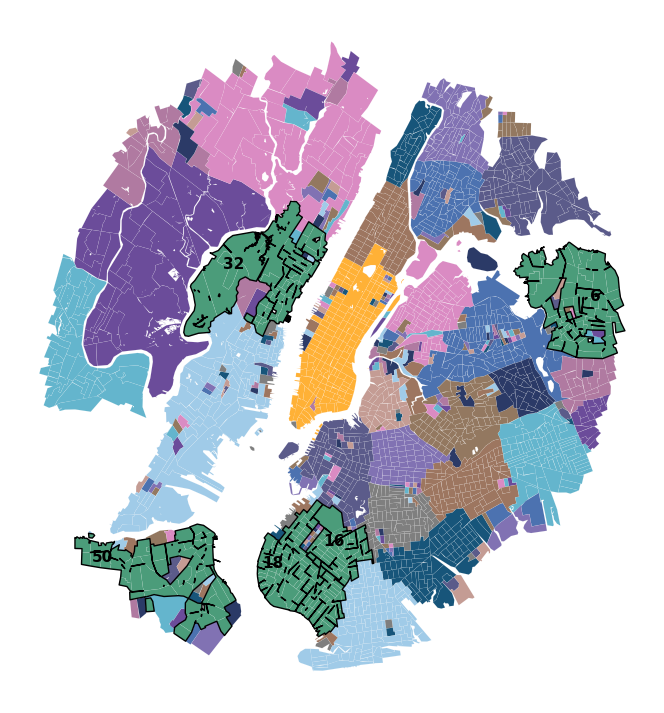

In [ ]:
g = gpd.read_file(data/"crz/demographics/tracts.geojson")
flows = pd.read_parquet(data/"crz/flows/flows.parquet")

g["GEOID"] = g["GEOID"].astype(str)
nodes = sorted(g["GEOID"])
idx = {n: i for i, n in enumerate(nodes)}

W = np.zeros((len(nodes), len(nodes)))
for s, t, wt in flows[["source", "target", "weight"]].itertuples(index=False):
    if s in idx and t in idx:
        W[idx[s], idx[t]] = wt

community = {r["GEOID"]: r["community"] for r in json.loads((data/"crz/consensus.json").read_text())}

g["community"] = g["GEOID"].map(community)


treated_comms = set(g.loc[g["treated"] == True, "community"].dropna().unique())
treated_ids = [idx[x] for x in g.loc[g["community"].isin(treated_comms), "GEOID"]]

Wd = diffusion_kernel(W)


sizes = g.dropna(subset=["community"]).groupby("community")["GEOID"].nunique()
candidates = [c for c in g.loc[g["universe"] & (~g["community"].isin(treated_comms)), "community"].dropna().unique()
              if sizes[c] >= 30]

feats = ["median_income", "race.white", "race.black", "trans.public"]
for f in feats:
    g[f] = pd.to_numeric(g[f], errors="coerce")

cd = g.dropna(subset=["community"]).groupby("community")[feats].mean().reset_index()
cd = cd.dropna(subset=feats, how="all")   
X = StandardScaler().fit_transform(cd[feats].fillna(0))

ps = np.clip(LogisticRegression(max_iter=1000).fit(X, cd["community"].isin(treated_comms).astype(int)).predict_proba(X)[:, 1], 1e-6, 1 - 1e-6)
cd["logit"] = np.log(ps / (1 - ps))
base = cd.loc[cd["community"].isin(treated_comms), "logit"].mean()
logit = dict(zip(cd["community"], cd["logit"]))

dist = []
for c in candidates:
    ino = [idx[x] for x in g.loc[g["community"] == c, "GEOID"]]
    score = Wd[np.ix_(ino, treated_ids)].mean()
    dist.append({"community": int(c), "dist": 1/score if score > 0 else np.nan,
                 "ps": abs(logit.get(c, np.nan) - base)})

dist = pd.DataFrame(dist); front = pareto(dist)
donors = [18, 6, 16, 32, 50]


plt.figure(figsize=(5, 4))
plt.scatter(dist["ps"], dist["dist"], color="lightgray")
plt.plot(front["ps"], front["dist"], "-o", color="steelblue")
sel = dist[dist.community.isin(donors)]
plt.scatter(sel["ps"], sel["dist"], color="seagreen", s=70, zorder=5, label="donors")
for _, r in dist.dropna().iterrows():
    plt.annotate(int(r["community"]), (r["ps"], r["dist"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
plt.yscale("log")
plt.xlabel("propensity distance")
plt.ylabel("network distance")
plt.legend()
plt.show()


sub = g[g["universe"] == True].dropna(subset=["community"]).copy()
sub["community"] = sub["community"].astype(int)

frac = sub.groupby("community")["treated"].apply(lambda s: (s == True).mean())
treated_zone = set(frac[frac >= 0.10].index)
donor_set = set(donors)

others = [c for c in sorted(sub["community"].unique()) if c not in treated_zone and c not in donor_set]

color = {c: PALETTE[i % len(PALETTE)] for i, c in enumerate(others)}
for c in treated_zone: 
    color[c] = TREAT
for c in donor_set: 
    color[c] = CONTROL

fig, ax = plt.subplots(figsize=(9, 9))
sub.plot(ax=ax, color=sub["community"].map(color), linewidth=0.05, edgecolor="white")

for c in donors:
    cg = sub[sub["community"] == c]
    if cg.empty:
        continue
    merged = cg.dissolve()
    merged.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1.0)
    pt = merged.representative_point().iloc[0]; ax.annotate(str(c), (pt.x, pt.y), ha="center", fontsize=11, weight="bold")


ax.set_axis_off()
plt.show()

## NYC Open Streets
POI network per site, RBConfiguration γ=2 — the Leiden ensemble + consensus is re-run here (as for Free Fare). Network distance uses the expanded graph. Treated communities via contamination (≥10% treated) and expansion (≥50% treated).

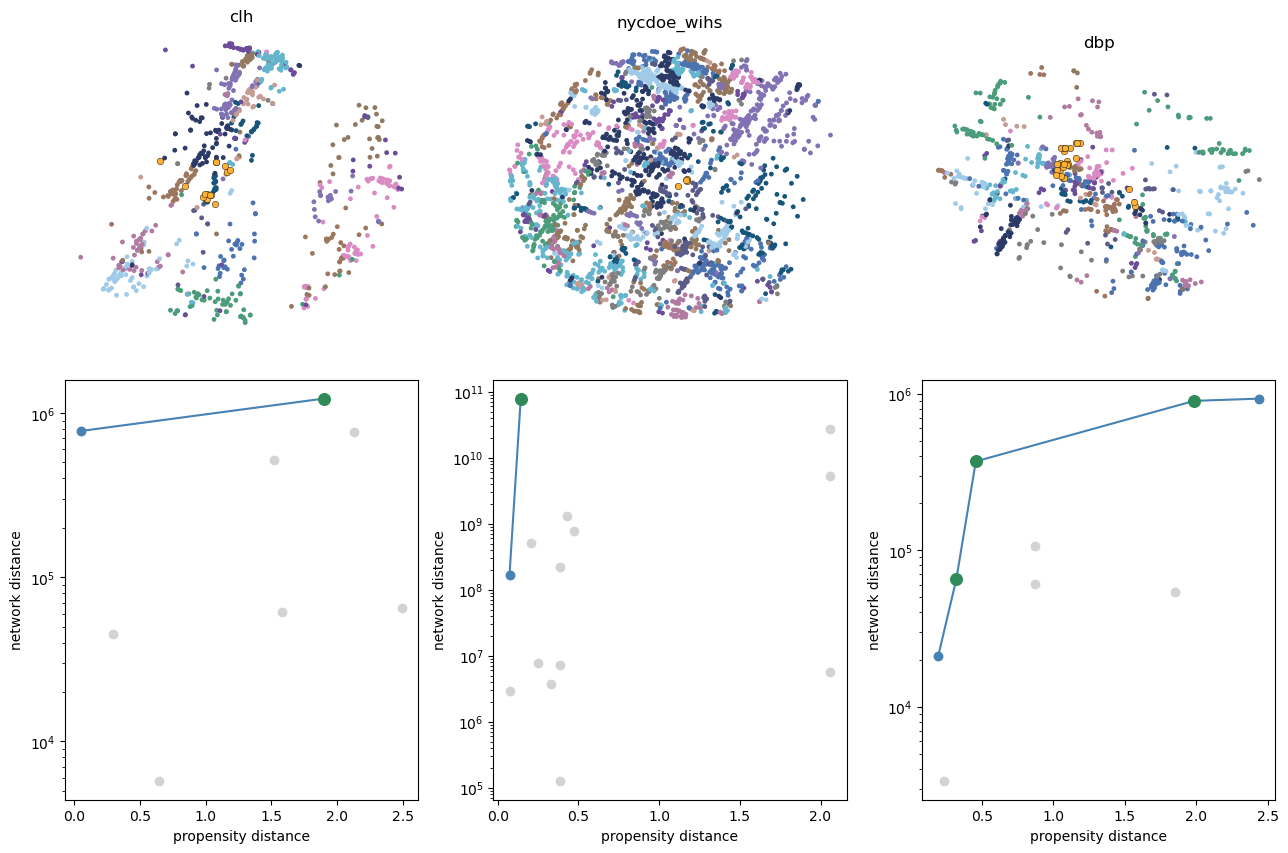

In [4]:
sites = [("clh", [6], 30), ("nycdoe_wihs", [34], 40), ("dbp", [9, 11, 25], 30)]

fig, axes = plt.subplots(2, 3, figsize=(13, 9))

for i, (org, donors, min_pois) in enumerate(sites):

    g = gpd.read_file(data/f"open_streets/{org}/demographics/pois.geojson")
    g["sg_id"] = g["sg_id"].astype(str)

    cf = pd.read_parquet(data/f"open_streets/{org}/flows/flows.parquet")

    cn = sorted(set(cf["source"].astype(str)) | set(cf["target"].astype(str)))

    ci = {n: k for k, n in enumerate(cn)}

    CW = np.zeros((len(cn), len(cn)))
    for s, t, wt in cf[["source", "target", "weight"]].itertuples(index=False):
        CW[ci[str(s)], ci[str(t)]] = wt

    er, ec = np.where(CW > 0)
    cgr = ig.Graph(n=len(cn), edges=list(zip(er.tolist(), ec.tolist())), directed=True)
    cgr.es["weight"] = CW[er, ec].tolist()

    mems = [leidenalg.find_partition(cgr, leidenalg.RBConfigurationVertexPartition, weights="weight", seed=sd, n_iterations=-1, resolution_parameter=2).membership for sd in range(100)]

    coas = np.zeros((len(cn), len(cn)))
    for m in mems:
        m = np.array(m)
        for k in np.unique(m):
            ii = np.where(m == k)[0]
            coas[np.ix_(ii, ii)] += 1

    coas /= len(mems)
    clab = fcluster(linkage(squareform(np.clip(1 - coas, 0, None), checks=False), "average"), 0.5, "distance")
    community = {cn[k]: int(clab[k]) for k in range(len(cn))}

    g["community"] = g["sg_id"].map(community)
    feats = ["weighted_income", "weighted_race.white", "weighted_race.black"]
    for c in feats: 
        g[c] = pd.to_numeric(g[c], errors="coerce")

    flows = pd.read_parquet(data/f"open_streets/{org}/flows_expanded.parquet")

    nodes = sorted(set(flows["source"]) | set(flows["target"]))
    idx = {n: i for i, n in enumerate(nodes)}

    W = np.zeros((len(nodes), len(nodes)))
    for s, t, wt in flows[["source", "target", "weight"]].itertuples(index=False):
        W[idx[s], idx[t]] = wt
    Wd = diffusion_kernel(W)

    direct = set(g.loc[g["treated"] == True, "sg_id"])
    fr = g.dropna(subset=["community"]).groupby("community")["treated"].mean()

    contaminated = set(g.loc[g["community"].isin(set(fr[fr >= 0.10].index)), "sg_id"])
    treated_comms = set(g.loc[g["sg_id"].isin(direct | contaminated), "community"].dropna().astype(int))
    expanded = set(fr[fr >= 0.5].index)
    treated_ids = [idx[x] for x in (direct | set(g.loc[g["community"].isin(expanded), "sg_id"])) if x in idx]

    cd = g.dropna(subset=["community"]).groupby("community")[feats].mean().reset_index()
    X = StandardScaler().fit_transform(cd[feats].fillna(0))
    ps = np.clip(LogisticRegression(max_iter=1000).fit(X, cd["community"].isin(treated_comms).astype(int)).predict_proba(X)[:, 1], 1e-6, 1 - 1e-6)
    cd["logit"] = np.log(ps / (1 - ps)); base = cd.loc[cd["community"].isin(treated_comms), "logit"].mean()
    sizes = g.dropna(subset=["community"]).groupby("community")["sg_id"].nunique()

    dist = []
    for c in cd["community"]:
        if c in treated_comms or sizes.get(c, 0) < min_pois: 
            continue
        ino = [idx[x] for x in g.loc[g["community"] == c, "sg_id"] if x in idx]
        score = Wd[np.ix_(ino, treated_ids)].mean() if ino and treated_ids else np.nan
        dist.append({"community": int(c), "dist": 1/score if score > 0 else np.nan,
                     "ps": abs(cd.loc[cd["community"] == c, "logit"].iloc[0] - base)})
        
    dist = pd.DataFrame(dist); front = pareto(dist)

    axm = axes[0, i]; gc = g.dropna(subset=["community"]).copy(); gc["community"] = gc["community"].astype(int)
    donor_set = set(donors)
    others = [c for c in sorted(gc["community"].unique()) if c not in donor_set]
    cmap_d = {c: PALETTE[j % len(PALETTE)] for j, c in enumerate(others)}

    for c in donor_set: 
        cmap_d[c] = CONTROL

    axm.scatter(gc.geometry.x, gc.geometry.y, c=[cmap_d[c] for c in gc["community"]], s=6)

    fr = gc.groupby("community")["treated"].mean(); expanded = set(fr[fr >= 0.5].index)
    tg = gc[(gc["treated"] == True) | gc["community"].isin(expanded)]
    axm.scatter(tg.geometry.x, tg.geometry.y, color=TREAT, s=22, edgecolor="black", linewidth=0.3, zorder=5)
    axm.set_aspect("equal"); axm.set_title(org); axm.set_axis_off()

    ax = axes[1, i]
    ax.scatter(dist["ps"], dist["dist"], color="lightgray")
    ax.plot(front["ps"], front["dist"], "-o", color="steelblue")
    sel = dist[dist.community.isin(donors)]
    ax.scatter(sel["ps"], sel["dist"], color="seagreen", s=70, zorder=5)
    ax.set_yscale("log")
    ax.set_xlabel("propensity distance")
    ax.set_ylabel("network distance")

plt.tight_layout(); plt.show()